# **4. Refining & Computing a Transcranial Evoked Potential (TEP)**

At the end of a preprocessing pipeline, you look at the result and assess if it contains signs of the brain activity of interest. 

In the case of an event-related design, the brain activity of interest is an evoked potential. In our case, it is a _transcranial_ evoked potential (TEP) &mdash; which, remember, is a fluctuation of the EEG signal that is evoked by a TMS pulse.

The computation of the TEP and its assessment can be preceded by a short sequence of preparatory steps. These last steps aim at removing some more noise and converting the data to a format where the evoked activity can stand out from the background. 

In the data-generating study, the last steps are:

- Low-pass filtering with a cut frequency of 70 Hz
- Rereferencing to the average reference
- Baseline correction

## **4.1. Preparatory Steps**

#### **Low-pass filtering** 

The code below applies a low-pass filter to the epoched data, with a cut frequency of 70 Hz. 

This means that all frequencies above 70 Hz will be attenuated, and all frequencies below 70 will remain as they are. This is useful because frequencies below 70 Hz are usually not of physiological interest, as they mostly generated by muscle contractions or instrumental noise. 

Reading /home/matteo/Documents/phd/brainstim-multimodal/data/post_ica_epo.fif ...
    Found the data of interest:
        t =   -1100.00 ...     500.00 ms
        0 CTF compensation matrices available
Not setting metadata
188 matching events found
No baseline correction applied
0 projection items activated
Setting up low-pass filter at 70 Hz

IIR filter parameters
---------------------
Butterworth lowpass zero-phase (two-pass forward and reverse) non-causal filter:
- Filter order 8 (effective, after forward-backward)
- Cutoff at 70.00 Hz: -6.02 dB

Not setting metadata
188 matching events found
No baseline correction applied
0 projection items activated


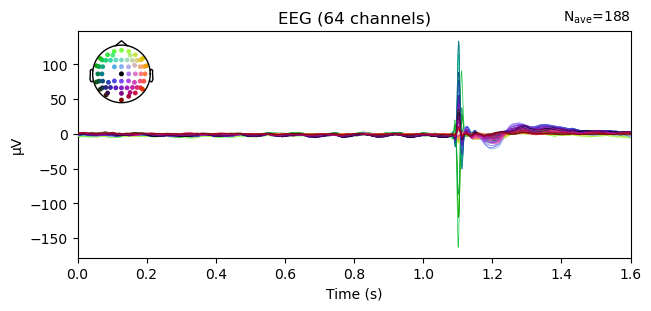

In [ ]:
post_ica_epochs = mne.read_epochs(fname="data/post_ica_epo.fif", 
                                        preload=True)

low_pass_filtered_data = mne.filter.filter_data(data=post_ica_epochs.get_data(),
                                                sfreq=post_ica_epochs.info["sfreq"],
                                                l_freq=None,
                                                h_freq=70.0,
                                                method="iir",
                                                iir_params=None,
                                                copy=True,
                                                phase="zero")
low_pass_filtered_epochs = mne.EpochsArray(data=low_pass_filtered_data,
                                           info=post_ica_epochs.info,
                                           baseline=None)
low_pass_filtered_tep = low_pass_filtered_epochs.average()
low_pass_filtered_tep.plot();

#### **Rereferencing**

Rereferencing is a common step in EEG preprocessing, and it is a very simple one: you just take one channel (the new reference) and subtract it to all others. 

Data enter any preprocessing pipeline with a built-in reference, which is the one applied online. If the reference electrode is strongly localised, signals from distant electrodes will be over-estimated with respect to neighbouring ones, creating a false impression of activity differences between the underlying generators. For example:

- Choosing an occipital reference like `Oz` will emphasize frontal signals, creating the false impression that frontal generators are more active than occipital ones
- Choosing a frontal reference like `AFz` will emphasize occipital signals, creating the false impression that occipital generators are more active than frontal ones
- Choosing a left-lateralised reference like `TP9` will emphasize right-hemisphere signals, creating the false impression that right generators are more active than left ones
- Choosing a right-lateralised reference like `TP10` will emphasize left-hemisphere signals, creating the false impression that left generators are more active than right ones

For this reason it is very important to choose a neutral reference &mdash; that is, one that does not over- or underestimate any signals. 

The average between the TP9 and TP10 electrodes (also called _digitally linked mastoids &mdash; DLM_) is widely considered to be a neutral reference, as it meets three important criteria:

- TP9 and TP10 are approximately halfway between the front and back of the head, so there is no risk of over- or underestimating frontal or occipital signals
- The reference is neither TP9 (which is left-lateralised) nor TP10 (which is right-lateralised), but their average. Therefore, it can be thought of as the midpoint between left and right
- TP9 and TP10 are located on the left and right mastoids, respectively. These are two bones, so they are approximately neutral from an electrophysiological point of view. Therefore, using them as reference (which implies losing their data) entails no loss of interesting information 

The online reference for our data was indeed the average of TP9 and TP10, so it was a neutral one. Nonetheless, the authors of the study chose to rereference to the average of all channels. 

The code below sets an average reference to the epoched data, using the `set_eeg_reference()` function provided by MNE. 

As can be seen, `set_eeg_reference()` returns two objects: the actual rereferenced data and the reference itself &mdash; which, in this case, is the reference of all channels.  

In [ ]:
rereferenced_epochs, reference = mne.set_eeg_reference(inst=low_pass_filtered_epochs,
                                                       ref_channels="average") 

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.


#### **Baseline correction** 

Baseline correction is the act of substracting a pre-stimulus mean to the post-stimulus signal, in order to represent the post-stimulus signal as a deviation from a baseline. 

The authors of the data-generating study computed the pre-stimulus mean between 100 ms pre-stimulus and 2 ms pre-stimulus. Therefore, the code below localizes those points on the temporal axis of the data.

In [ ]:
TIME_OF_EVENT = 1.1                             # seconds
baseline_window_start = TIME_OF_EVENT - 0.100   # seconds
baseline_window_end = TIME_OF_EVENT - 0.002     # seconds

Having defined the start and end of the baseline window, we can use it for baseline correction and, subsequenly, compute a TEP for visualization as usual. The code below does just that:

Applying baseline correction (mode: mean)


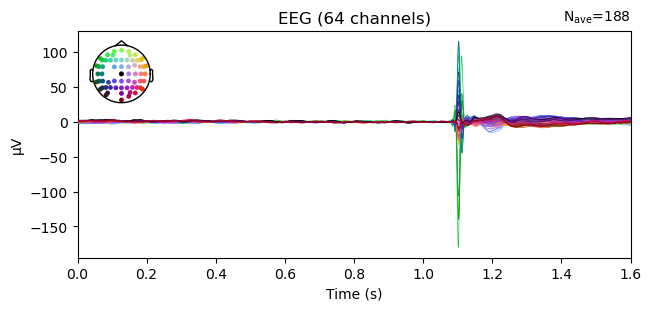

In [ ]:
baseline_corrected_epochs = rereferenced_epochs.apply_baseline(baseline=(baseline_window_start, baseline_window_end))
baseline_corrected_tep = baseline_corrected_epochs.average()
baseline_corrected_tep.plot();

## **4.2. Computation of the TEP** 

This is the simplest part, as an evoked potential is merely an average over epochs. The code below computes such average after cropping the pre-stimulus window to 100 ms for more visual clarity. 

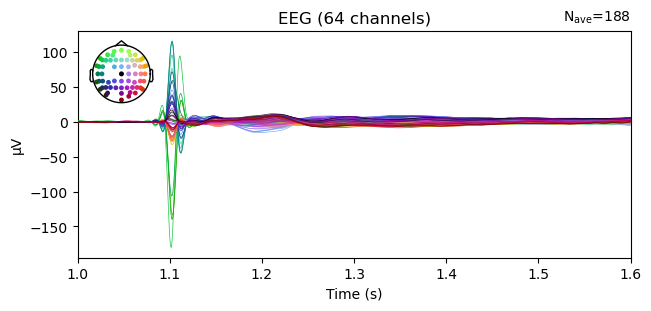

In [ ]:
final_epochs = baseline_corrected_epochs.crop(tmin=1.0,
                                              tmax=1.6,
                                              include_tmax=True)
final_tep = final_epochs.average()
final_tep.plot();

# **Closing Remarks**

As said in the beginning, preprocessing is a complex and multi-step process. This notebook sketched a minimal preprocessing pipeline with the goal of demonstrating some of that complexity through some of the most commonly used operations. It is important to underline that the result is an introductory presentation, not a state-of-art pipeline producing state-of-the-art results. In fact, the preprocessed data still contain several signs of muscle and instrumental artefacts that preprocessing operations could not eliminate. 

The data used for this activity were particularly noisy. While suboptimal from a scientific point of view, such a large amount of noise is a great educational opportunity because it exposed you to clear examples of the most common artefacts in (TMS-)EEG recordings. 

---

In a real-world context, the pipeline sketched above (or any other pipeline) would be applied to data from more than one subject. This could be achieved very simply by iterating over subject files according to the following logic:

```
for subject in subject_list, apply whole pipeline
``` 

This would result in one "clean" TEP per subject, and all such TEPs would be averaged to obtain a sample mean. Like all evoked potentials, this sample mean would be characterised by a latency and an amplitude that might be of scientific interest: for example, the latency might be a proxy for conduction delay along a given fibre bundle, while the amplitude might be a proxy for the amplitude of the cortical response to stimulation. 

Typically, TMS-EEG experiments include more than one condition: for example, they might include stimulation over area $A$ and stimulation over area $B$, or stimulation of a same area with intensities $I_1$ and $I_2$. In these cases, the object of interest is usually the difference in the latency and amplitude of TEPs, as it might carry interesting information: for example, observing a larger TEP after stimulating at a larger intensity would suggest that larger stimulation evokes a larger cortical response. 

---

One theme that emerged during the construction of this pipeline is that preprocessing is not based on objective ground truths. This is due in part to the inherent complexity of this process &mdash; where different data are generated by different stimulation protocols applied in different environmental conditions, making it difficult to find a universally powerful pipeline &mdash; and in part to a lack of agreement in the TMS-EEG community. Compared to a few years ago, however, there is widespread awareness that preprocessing choices do impact the quality and scientific value of data: for example, [Bertazzoli et al. (2021)](https://doi.org/10.1016/j.neuroimage.2021.118272) showed that applying different preprocessing pipelines to the same TMS-EEG data can lead to TEPs of different amplitude, while [Brancaccio et al., 2024](https://doi.org/10.1016/j.neuroimage.2024.120874) showed that not all pipelines can retrieve the same synthetic ground-truth (that is, a computer-generated artificial signal) with the same accuracy. 

Understanding the impact of preprocessing on TMS-EEG (and, more generally, neuroscientific) data is an open problem, as is the formulation of strategies to standardise procedures and eliminate any subjective choices (see for example [Pion-Tonachini et al., 2019](https://doi.org/10.1016/j.neuroimage.2019.05.026)). If you are interested in this field, you might find plenty of room for research in your future! 